# FinGame — анализ рынка аналогов

**Автор:** Данис Шарафутдинов  
**Данные:** публичные метрики App Store и Google Play на 25.11.2026

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ferlios/FinGame/blob/main/analysis/FinGame_analysis.ipynb)

> FinGame ещё не запущен. Это анализ существующих аналогов, а не данные использования нашего продукта.
>
> **Запуск:** Runtime → Run all. Ноутбук сам склонирует репозиторий.

In [1]:
# В Colab: Runtime -> Run all. Локально: открыть из папки analysis/.
import os
import subprocess
from pathlib import Path

REPO_URL = "https://github.com/Ferlios/FinGame.git"

def find_repo():
    for candidate in [Path.cwd(), Path.cwd().parent, Path("/content/FinGame")]:
        if (candidate / "analysis" / "data" / "analogs_market.csv").exists():
            return candidate.resolve()
    return None

repo = find_repo()
if repo is None:
    target = Path("/content/FinGame")
    if target.exists():
        subprocess.run(["git", "-C", str(target), "pull", "--ff-only"], check=False)
    else:
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(target)], check=True)
    repo = target.resolve()

os.chdir(repo)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from IPython.display import display

%matplotlib inline

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.edgecolor": "#d1d5db",
    "axes.facecolor": "white",
    "figure.facecolor": "white",
    "xtick.color": "#6b7280",
    "ytick.color": "#6b7280",
    "text.color": "#1f2937",
    "axes.labelcolor": "#1f2937",
    "grid.color": "#e5e7eb",
    "grid.linewidth": 0.7,
    "legend.frameon": False,
})

VIOLET = "#7c3aed"
TEAL = "#0d9488"
AMBER = "#f59e0b"
PINK = "#ec4899"
RED = "#ef4444"
MUTED = "#6b7280"

SEGMENT_COLORS = {
    "Прямой аналог": VIOLET,
    "Детские и семейные финансы": TEAL,
    "Геймификация": AMBER,
    "Питомец": PINK,
}

## Данные

In [3]:
df = pd.read_csv(repo / "analysis" / "data" / "analogs_market.csv", encoding="utf-8-sig")

def parse_installs(value):
    if pd.isna(value) or str(value).strip() == "":
        return np.nan
    text = str(value).replace("+", "").strip().upper()
    if text.endswith("M"):
        return float(text[:-1])
    if text.endswith("K"):
        return float(text[:-1]) / 1000
    return float(text)

df["ios_rating"] = pd.to_numeric(df["ios_rating"], errors="coerce")
df["ios_ratings"] = pd.to_numeric(df["ios_ratings"], errors="coerce")
df["android_rating"] = pd.to_numeric(df["android_rating"], errors="coerce")
df["android_installs_m"] = df["android_installs"].map(parse_installs)
df["release_year"] = pd.to_numeric(df["release_year"], errors="coerce")

feature_cols = ["pet", "quests", "levels", "achievements", "streaks", "savings", "mini_games", "analytics"]
feature_ru = {
    "pet": "Питомец",
    "quests": "Квесты",
    "levels": "Уровни",
    "achievements": "Достижения",
    "streaks": "Стрики",
    "savings": "Накопления",
    "mini_games": "Мини-игры",
    "analytics": "Аналитика",
}
df["features_count"] = df[feature_cols].sum(axis=1)
df["has_metrics"] = df["ios_ratings"].gt(0) | df["android_installs_m"].notna()

short = {
    "Fortune City: Expense Tracker": "Fortune City",
    "Bread: Gamified Budget Tracker": "Bread",
    "BudgetQuest": "BudgetQuest",
    "Eira - Budget & Money Coach": "Eira",
    "Cleo AI: Cash Advance & Budget": "Cleo",
    "Step: All-In-One Money App": "Step",
    "Greenlight: For Families": "Greenlight",
    "BusyKid": "BusyKid",
    "GoHenry by Acorns Kids Banking": "GoHenry",
    "Qapital: The Money Saving App": "Qapital",
    "Habitica: Gamified Taskmanager": "Habitica",
    "Finch: Self-Care Pet": "Finch",
    "Gotcha": "Gotcha",
    "Бюджетный питомец": "Бюдж. питомец",
}
df["short"] = df["app"].map(short).fillna(df["app"])

In [4]:
table = df[[
    "app", "segment", "platform", "ios_rating", "ios_ratings",
    "android_rating", "android_installs", "release_year", "developer"
]].copy()
table.columns = ["Приложение", "Сегмент", "Платформы", "Рейтинг iOS", "Оценок iOS",
                 "Рейтинг Android", "Установки", "Год", "Разработчик"]
display(
    table.style
    .hide(axis="index")
    .format({
        "Рейтинг iOS": lambda v: "—" if pd.isna(v) else f"{v:.2f}",
        "Оценок iOS": lambda v: "—" if pd.isna(v) or v == 0 else f"{int(v):,}".replace(",", "\u00a0"),
        "Рейтинг Android": lambda v: "—" if pd.isna(v) else f"{v:.1f}",
        "Установки": lambda v: "—" if pd.isna(v) else str(v),
        "Год": lambda v: "—" if pd.isna(v) else str(int(v)),
    }, na_rep="—")
    .set_properties(**{"font-size": "11px"})
)

Приложение,Сегмент,Платформы,Рейтинг iOS,Оценок iOS,Рейтинг Android,Установки,Год,Разработчик
Fortune City: Expense Tracker,Прямой аналог,iOS + Android,4.52,4 991,4.2,1M+,2017,SPARKFUL
Bread: Gamified Budget Tracker,Прямой аналог,iOS,4.42,71,—,—,2024,Bread Money
BudgetQuest,Прямой аналог,iOS,5.00,2,—,—,2026,Md HASAN
Eira - Budget & Money Coach,Прямой аналог,iOS,—,—,—,—,2025,Alina Bezchotnikova Kjøs
Cleo AI: Cash Advance & Budget,Прямой аналог,iOS + Android,4.67,271 209,4.6,5M+,2019,Cleo AI Ltd
Step: All-In-One Money App,Детские и семейные финансы,iOS + Android,4.74,82 562,4.3,1M+,2019,Step Mobile Inc.
Greenlight: For Families,Детские и семейные финансы,iOS + Android,4.80,491 470,4.7,1M+,2016,Greenlight Financial Technology
BusyKid,Детские и семейные финансы,iOS + Android,3.39,1 508,3.7,500K+,2019,BusyKid Inc.
GoHenry by Acorns Kids Banking,Детские и семейные финансы,iOS + Android,4.48,14 559,4.6,1M+,2018,gohenry Ltd
Qapital: The Money Saving App,Прямой аналог,iOS + Android,4.80,85 905,4.2,1M+,2015,Qapital LLC


In [5]:
store = {
    "iOS": "App Store",
    "iOS + Android": "App Store + Google Play",
    "Концепт (Devpost)": "Devpost",
    "RuStore": "RuStore",
}
sources = df[["short", "platform", "note"]].copy()
sources["Источник"] = sources["platform"].map(store).fillna(sources["platform"])
display(
    sources[["short", "Источник", "note"]]
    .rename(columns={"short": "Приложение", "note": "Комментарий"})
    .style.hide(axis="index")
    .set_properties(**{"font-size": "11px"})
)

Приложение,Источник,Комментарий
Fortune City,App Store + Google Play,Город растёт от записей трат
Bread,App Store,"Питомец Брэд, коллекционные персонажи"
BudgetQuest,App Store,"Новое приложение, мало оценок"
Eira,App Store,"17 AI-компаньонов, оценок пока нет"
Cleo,App Store + Google Play,AI-персонаж и чат вместо калькулятора
Step,App Store + Google Play,Банк для подростков
Greenlight,App Store + Google Play,Семейные карманные деньги и накопления
BusyKid,App Store + Google Play,Домашние дела как источник дохода
GoHenry,App Store + Google Play,Миссии и карманные деньги для детей
Qapital,App Store + Google Play,Правила и цели накоплений


Полные ссылки на карточки приложений — в `analysis/data/analogs_market.csv`, колонка `source`.

## Охват рынка

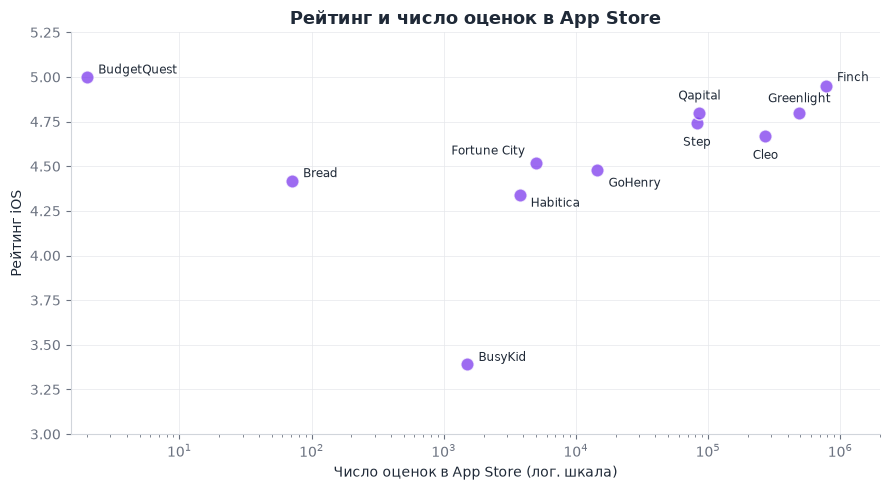

In [6]:
ios = df[df["ios_ratings"] > 0].copy()

offsets = {
    "BudgetQuest": (8, 5, "left"),
    "Bread": (8, 5, "left"),
    "Habitica": (8, -6, "left"),
    "Fortune City": (-8, 8, "right"),
    "GoHenry": (8, -10, "left"),
    "Qapital": (0, 12, "center"),
    "Step": (0, -14, "center"),
    "Cleo": (0, -14, "center"),
    "Greenlight": (0, 10, "center"),
    "Finch": (8, 6, "left"),
    "BusyKid": (8, 5, "left"),
}

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(ios["ios_ratings"], ios["ios_rating"], s=90, color=VIOLET, alpha=0.75, edgecolor="white")
for _, row in ios.iterrows():
    dx, dy, ha = offsets.get(row["short"], (8, 5, "left"))
    ax.annotate(row["short"], (row["ios_ratings"], row["ios_rating"]),
                xytext=(dx, dy), textcoords="offset points", fontsize=8.5,
                ha=ha, va="center")
ax.set_xscale("log")
ax.set_xlim(1.5, 2_000_000)
ax.set_xlabel("Число оценок в App Store (лог. шкала)")
ax.set_ylabel("Рейтинг iOS")
ax.set_ylim(3.0, 5.25)
ax.set_title("Рейтинг и число оценок в App Store")
ax.grid(alpha=0.7)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

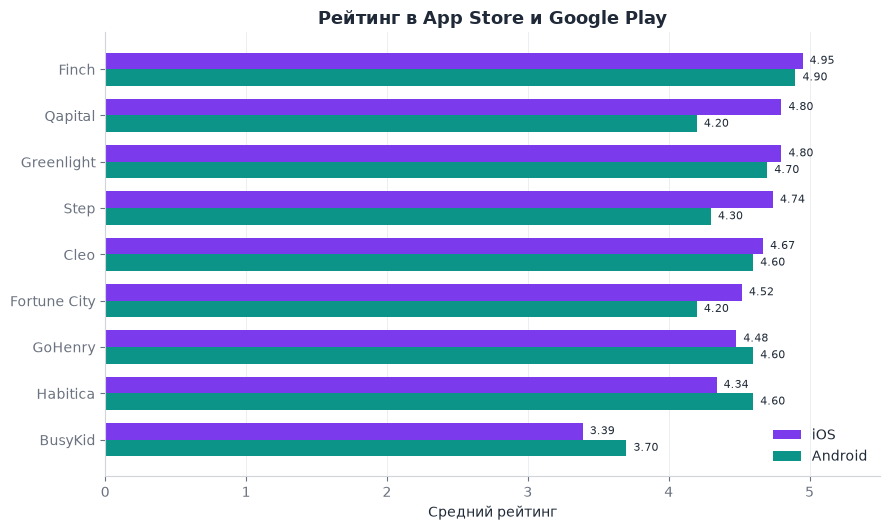

In [7]:
both = df.dropna(subset=["ios_rating", "android_rating"]).sort_values("ios_rating")
y = np.arange(len(both))
h = 0.36

fig, ax = plt.subplots(figsize=(9, 5.4))
ax.barh(y + h / 2, both["ios_rating"], height=h, color=VIOLET, label="iOS")
ax.barh(y - h / 2, both["android_rating"], height=h, color=TEAL, label="Android")
for i, (_, row) in enumerate(both.iterrows()):
    ax.text(row["ios_rating"] + 0.05, i + h / 2, f"{row['ios_rating']:.2f}", va="center", fontsize=8)
    ax.text(row["android_rating"] + 0.05, i - h / 2, f"{row['android_rating']:.2f}", va="center", fontsize=8)
ax.set_yticks(y)
ax.set_yticklabels(both["short"])
ax.set_xlim(0, 5.5)
ax.set_xlabel("Средний рейтинг")
ax.set_title("Рейтинг в App Store и Google Play")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.7)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

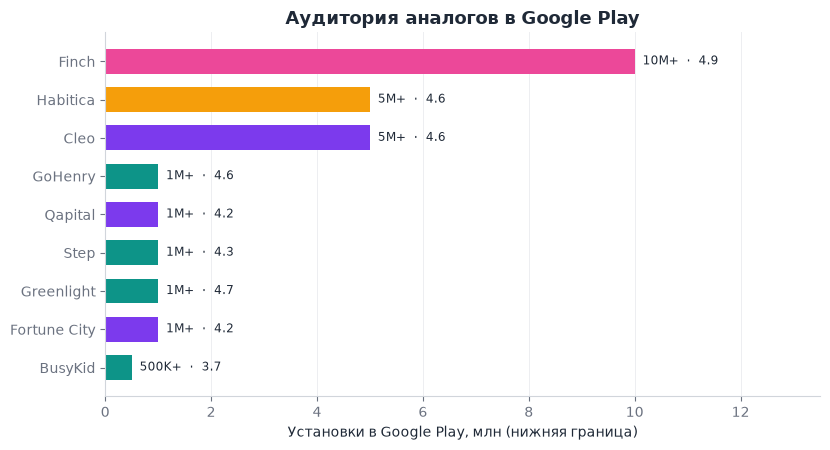

In [8]:
android = df.dropna(subset=["android_installs_m"]).sort_values("android_installs_m")

fig, ax = plt.subplots(figsize=(8.4, 4.6))
colors = [SEGMENT_COLORS.get(s, MUTED) for s in android["segment"]]
bars = ax.barh(android["short"], android["android_installs_m"], color=colors, height=0.65)
for bar, (_, row) in zip(bars, android.iterrows()):
    ax.text(bar.get_width() + 0.15, bar.get_y() + bar.get_height() / 2,
            f"{row['android_installs']}  ·  {row['android_rating']:.1f}", va="center", fontsize=8.5)
ax.set_xlim(0, android["android_installs_m"].max() * 1.35)
ax.set_xlabel("Установки в Google Play, млн (нижняя граница)")
ax.set_title("Аудитория аналогов в Google Play")
ax.grid(axis="x", alpha=0.7)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

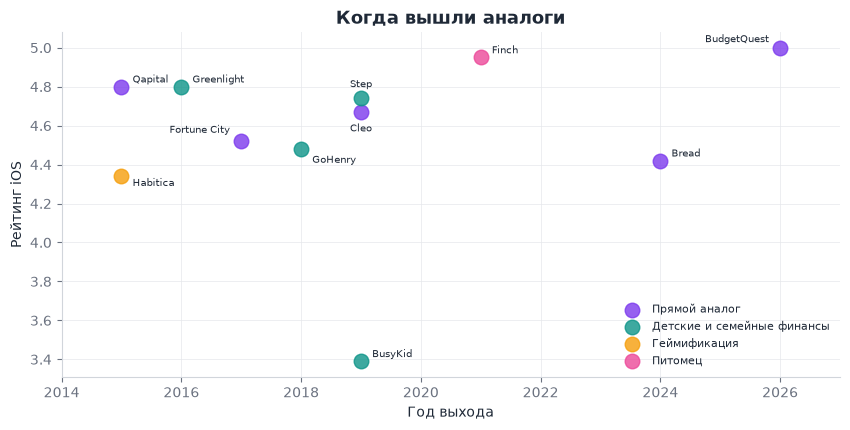

In [9]:
timeline = df.dropna(subset=["release_year"]).copy()
timeline["release_year"] = timeline["release_year"].astype(int)

offsets = {
    "Qapital": (8, 5, "left"),
    "Greenlight": (8, 5, "left"),
    "Habitica": (8, -5, "left"),
    "Fortune City": (-8, 8, "right"),
    "GoHenry": (8, -8, "left"),
    "Step": (0, 10, "center"),
    "Cleo": (0, -12, "center"),
    "BusyKid": (8, 5, "left"),
    "Finch": (8, 5, "left"),
    "Bread": (8, 5, "left"),
    "BudgetQuest": (-8, 6, "right"),
}

fig, ax = plt.subplots(figsize=(8.6, 4.4))
for segment, color in SEGMENT_COLORS.items():
    subset = timeline[timeline["segment"] == segment]
    ax.scatter(subset["release_year"], subset["ios_rating"], s=110, color=color, label=segment, alpha=0.8)
for _, row in timeline.iterrows():
    dx, dy, ha = offsets.get(row["short"], (8, 5, "left"))
    ax.annotate(row["short"], (row["release_year"], row["ios_rating"]),
                xytext=(dx, dy), textcoords="offset points", fontsize=7.5,
                ha=ha, va="center")
ax.set_xlim(2014, 2027)
ax.set_xlabel("Год выхода")
ax.set_ylabel("Рейтинг iOS")
ax.set_title("Когда вышли аналоги")
ax.legend(fontsize=8, loc="lower right")
ax.grid(alpha=0.7)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Механики

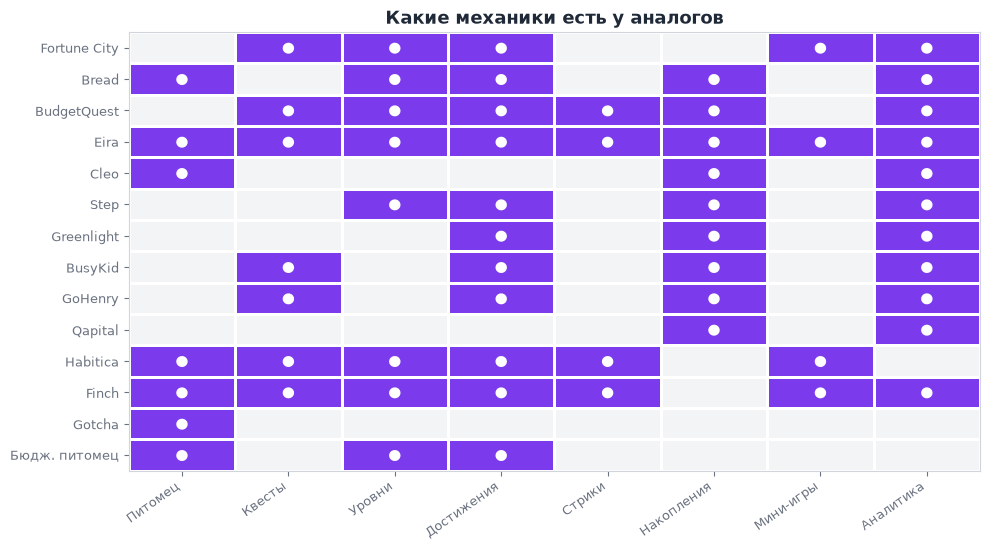

In [10]:
from matplotlib.colors import ListedColormap

matrix = df.set_index("short")[feature_cols].copy()
matrix.columns = [feature_ru[c] for c in matrix.columns]

fig, ax = plt.subplots(figsize=(10, 5.6))
ax.pcolormesh(
    np.arange(len(matrix.columns) + 1) - 0.5,
    np.arange(len(matrix.index) + 1) - 0.5,
    matrix.values,
    cmap=ListedColormap(["#f3f4f6", VIOLET]),
    vmin=-0.5, vmax=1.5,
    edgecolors="white", linewidth=2,
)
ax.invert_yaxis()
ax.set_xticks(range(len(matrix.columns)))
ax.set_xticklabels(matrix.columns, rotation=35, ha="right", fontsize=9)
ax.set_yticks(range(len(matrix.index)))
ax.set_yticklabels(matrix.index, fontsize=9)
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        if matrix.values[i, j]:
            ax.text(j, i, "●", ha="center", va="center", color="white", fontsize=11)
ax.set_title("Какие механики есть у аналогов")
plt.tight_layout()
plt.show()

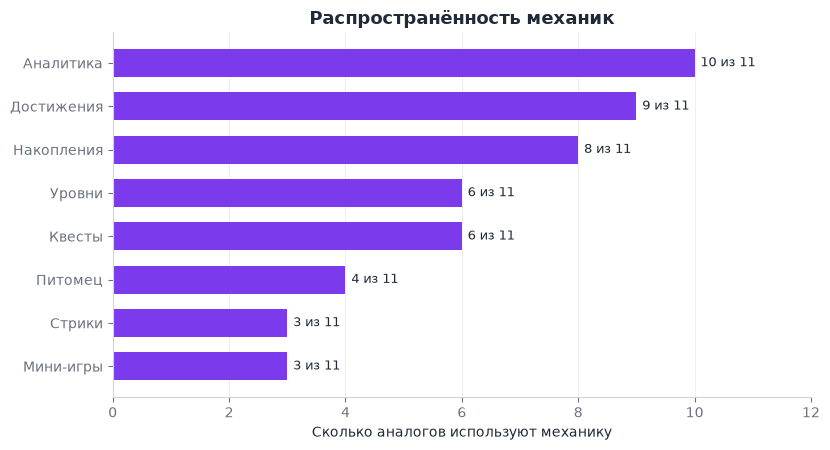

In [11]:
measured = df[df["has_metrics"]]
counts = measured[feature_cols].sum().sort_values()
labels = [feature_ru[c] for c in counts.index]

fig, ax = plt.subplots(figsize=(8.4, 4.6))
bars = ax.barh(labels, counts.values, color=VIOLET, height=0.65)
for bar, value in zip(bars, counts.values):
    ax.text(value + 0.1, bar.get_y() + bar.get_height() / 2, f"{int(value)} из {len(measured)}", va="center", fontsize=9)
ax.set_xlim(0, len(measured) + 1)
ax.set_xlabel("Сколько аналогов используют механику")
ax.set_title("Распространённость механик")
ax.grid(axis="x", alpha=0.7)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

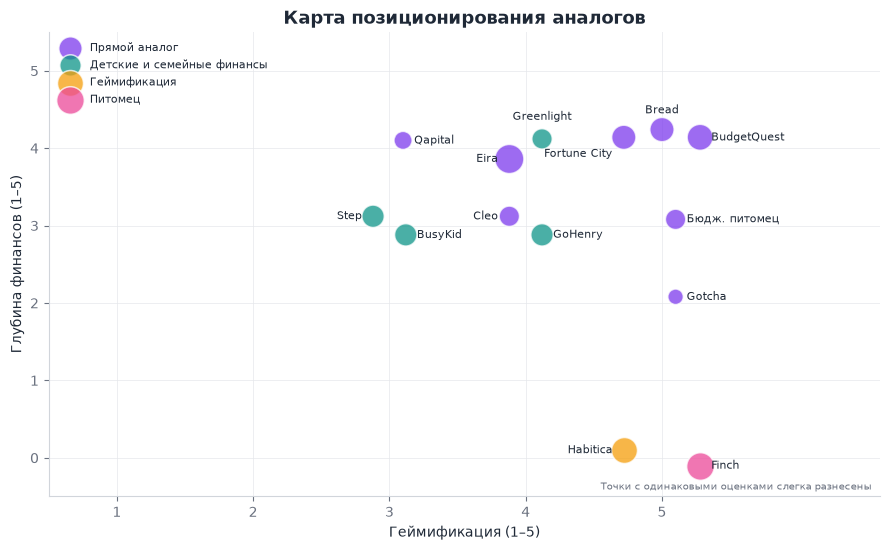

In [12]:
# Небольшое смещение совпадающих точек и подписей, чтобы всё читалось
dodge = {
    "Fortune City": (-0.28, 0.14, -8, -12, "right"),
    "Bread": (0.00, 0.24, 0, 14, "center"),
    "BudgetQuest": (0.28, 0.14, 8, 0, "left"),
    "Eira": (-0.12, -0.14, -8, 0, "right"),
    "Greenlight": (0.12, 0.12, 0, 16, "center"),
    "Cleo": (-0.12, 0.12, -8, 0, "right"),
    "GoHenry": (0.12, -0.12, 8, 0, "left"),
    "Step": (-0.12, 0.12, -8, 0, "right"),
    "BusyKid": (0.12, -0.12, 8, 0, "left"),
    "Habitica": (-0.28, 0.10, -8, 0, "right"),
    "Finch": (0.28, -0.10, 8, 0, "left"),
    "Qapital": (0.10, 0.10, 8, 0, "left"),
    "Gotcha": (0.10, 0.08, 8, 0, "left"),
    "Бюдж. питомец": (0.10, 0.08, 8, 0, "left"),
}

x = df["gamification"] + df["short"].map(lambda s: dodge.get(s, (0, 0, 0, 0, "left"))[0])
y = df["finance_depth"] + df["short"].map(lambda s: dodge.get(s, (0, 0, 0, 0, "left"))[1])

fig, ax = plt.subplots(figsize=(9, 5.6))
for segment, color in SEGMENT_COLORS.items():
    mask = df["segment"] == segment
    if not mask.any():
        continue
    ax.scatter(
        x[mask], y[mask],
        s=80 + df.loc[mask, "features_count"] * 45,
        color=color, alpha=0.75, edgecolor="white", linewidth=1.1, label=segment,
    )
for _, row in df.iterrows():
    _, _, ox, oy, ha = dodge.get(row["short"], (0, 0, 8, 0, "left"))
    ax.annotate(row["short"], (x[row.name], y[row.name]), xytext=(ox, oy),
                textcoords="offset points", fontsize=8, ha=ha, va="center")
ax.set_xlim(0.5, 6.6)
ax.set_ylim(-0.5, 5.5)
ax.set_xticks(range(1, 6))
ax.set_yticks(range(0, 6))
ax.set_xlabel("Геймификация (1–5)")
ax.set_ylabel("Глубина финансов (1–5)")
ax.set_title("Карта позиционирования аналогов")
ax.text(0.99, 0.01, "Точки с одинаковыми оценками слегка разнесены",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=7, color=MUTED)
ax.legend(fontsize=8, loc="upper left")
ax.grid(alpha=0.7)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Связи между метриками

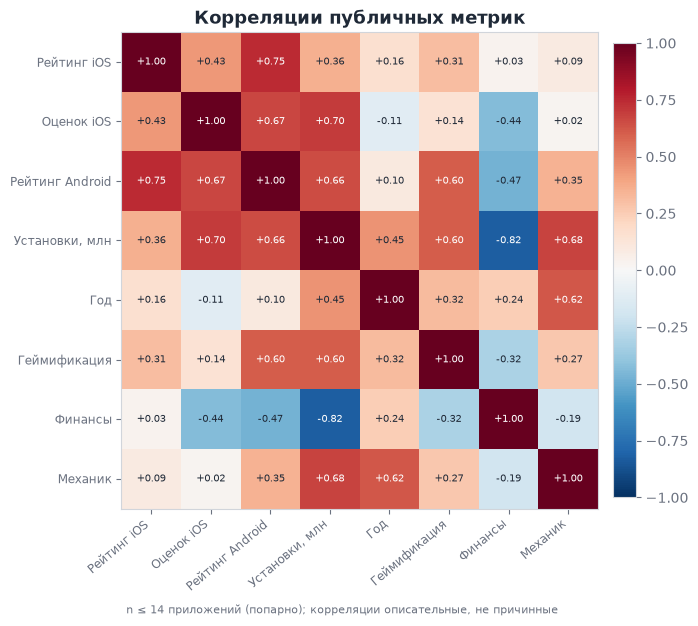

In [13]:
numeric = df[["ios_rating", "ios_ratings", "android_rating", "android_installs_m",
              "release_year", "gamification", "finance_depth", "features_count"]].copy()
numeric.columns = ["Рейтинг iOS", "Оценок iOS", "Рейтинг Android", "Установки, млн",
                   "Год", "Геймификация", "Финансы", "Механик"]
corr = numeric.corr()

fig, ax = plt.subplots(figsize=(8.4, 6.4))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=40, ha="right", fontsize=8.5)
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns, fontsize=8.5)
for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        value = corr.values[i, j]
        if not np.isnan(value):
            ax.text(j, i, f"{value:+.2f}", ha="center", va="center", fontsize=7.5,
                    color="white" if abs(value) > 0.55 else "#1f2937")
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
ax.set_title("Корреляции публичных метрик")
ax.text(0.01, -0.22, f"n ≤ {len(df)} приложений (попарно); корреляции описательные, не причинные",
        transform=ax.transAxes, fontsize=8, color=MUTED)
plt.tight_layout()
plt.show()

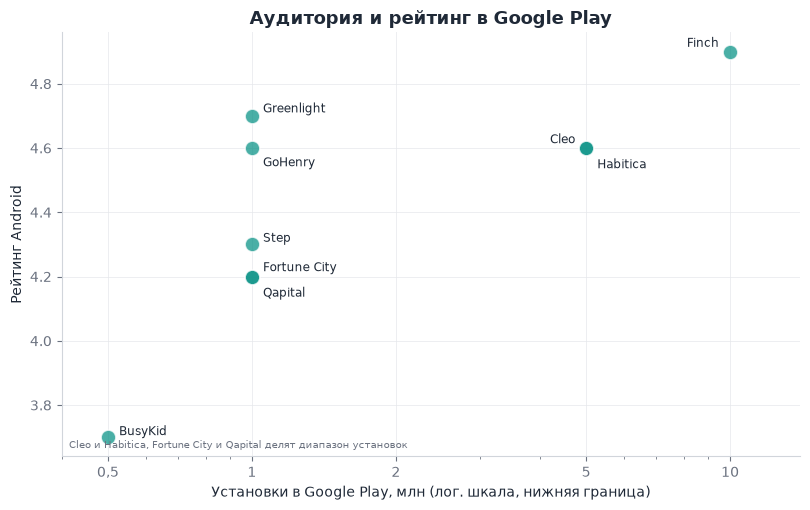

In [14]:
android = df.dropna(subset=["android_installs_m", "android_rating"])

offsets = {
    "Fortune City": (8, 6, "left"),
    "Qapital": (8, -12, "left"),
    "Greenlight": (8, 5, "left"),
    "GoHenry": (8, -11, "left"),
    "Step": (8, 4, "left"),
    "BusyKid": (8, 4, "left"),
    "Cleo": (-8, 6, "right"),
    "Habitica": (8, -12, "left"),
    "Finch": (-8, 6, "right"),
}

fig, ax = plt.subplots(figsize=(8.2, 5.2))
ax.scatter(android["android_installs_m"], android["android_rating"],
           s=110, color=TEAL, alpha=0.75, edgecolor="white")
for _, row in android.iterrows():
    dx, dy, ha = offsets.get(row["short"], (8, 5, "left"))
    ax.annotate(row["short"], (row["android_installs_m"], row["android_rating"]),
                xytext=(dx, dy), textcoords="offset points", fontsize=8.5,
                ha=ha, va="center")
ax.set_xscale("log")
ax.set_xticks([0.5, 1, 2, 5, 10])
ax.set_xticklabels(["0,5", "1", "2", "5", "10"])
ax.set_xlim(0.4, 14)
ax.set_xlabel("Установки в Google Play, млн (лог. шкала, нижняя граница)")
ax.set_ylabel("Рейтинг Android")
ax.set_title("Аудитория и рейтинг в Google Play")
ax.text(0.01, 0.02, "Cleo и Habitica, Fortune City и Qapital делят диапазон установок",
        transform=ax.transAxes, fontsize=7, color=MUTED)
ax.grid(alpha=0.7)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Итоговые таблицы

In [15]:
by_audience = df.dropna(subset=["android_installs_m"]).sort_values("android_installs_m", ascending=False)
display(by_audience[["short", "android_installs", "android_rating", "ios_rating", "segment"]]
        .rename(columns={"short": "Приложение", "android_installs": "Установки",
                         "android_rating": "Android", "ios_rating": "iOS", "segment": "Сегмент"})
        .head(5).reset_index(drop=True))

,Приложение,Установки,Android,iOS,Сегмент
0,Finch,10M+,4.9,4.95,Питомец
1,Habitica,5M+,4.6,4.34,Геймификация
2,Cleo,5M+,4.6,4.67,Прямой аналог
3,Fortune City,1M+,4.2,4.52,Прямой аналог
4,Step,1M+,4.3,4.74,Детские и семейные финансы


In [16]:
by_rating = df[df["ios_ratings"] >= 100].sort_values("ios_rating", ascending=False)
display(by_rating[["short", "ios_rating", "ios_ratings", "segment"]]
        .rename(columns={"short": "Приложение", "ios_rating": "Рейтинг iOS",
                         "ios_ratings": "Оценок", "segment": "Сегмент"})
        .head(5).reset_index(drop=True))

,Приложение,Рейтинг iOS,Оценок,Сегмент
0,Finch,4.95,779182.0,Питомец
1,Qapital,4.80,85905.0,Прямой аналог
2,Greenlight,4.80,491470.0,Детские и семейные финансы
3,Step,4.74,82562.0,Детские и семейные финансы
4,Cleo,4.67,271209.0,Прямой аналог


In [17]:
share = measured[feature_cols].mean()
gap = pd.DataFrame({
    "Механика": [feature_ru[c] for c in feature_cols],
    "Доля аналогов": [share[c] for c in feature_cols],
    "FinGame": 1,
})
gap["Свободное место"] = np.where(
    gap["Доля аналогов"] < 0.4, "высокое",
    np.where(gap["Доля аналогов"] < 0.7, "среднее", "низкое"),
)
gap["Доля аналогов"] = gap["Доля аналогов"].map(lambda v: f"{v * 100:.0f}%")
display(gap.sort_values("Доля аналогов", key=lambda s: s.str.rstrip("%").astype(int)).reset_index(drop=True))

,Механика,Доля аналогов,FinGame,Свободное место
0,Мини-игры,27%,1,высокое
1,Стрики,27%,1,высокое
2,Питомец,36%,1,высокое
3,Квесты,55%,1,среднее
4,Уровни,55%,1,среднее
5,Накопления,73%,1,низкое
6,Достижения,82%,1,низкое
7,Аналитика,91%,1,низкое


## Выводы

- Самые крупные аудитории в Google Play — Finch (10M+), Cleo и Habitica (5M+), но это не финансовые продукты.
- Среди финансовых аналогов лидируют Greenlight (491 тыс. оценок iOS), Cleo (271 тыс.) и Qapital (86 тыс.).
- Fortune City — ближайший аналог по идее «траты → развитие мира»: 4,52 в iOS и 1M+ установок в Android.
- Bread и BudgetQuest показывают, что ниша «питомец + бюджет» существует, но продукты молодые и с малой аудиторией.
- У большинства аналогов есть уровни, достижения и накопления. Реже всего встречается сочетание питомца, квестов и реальной аналитики трат.
- Высокий рейтинг не равен большой аудитории: у BudgetQuest 5,0 при 2 оценках, у Finch 4,95 при 779 тыс. оценок.

## Ограничения

- Число оценок — не скачивания; это нижняя оценка активной аудитории.
- Установки Google Play даны диапазонами.
- Оценки механик 1–5 субъективны и основаны на публичных описаниях.
- Gotcha и «Бюджетный питомец» не имеют проверяемых метрик и не участвуют в графиках рыночных метрик; их механики взяты из публичных описаний.
- Данные на 25.11.2026 и могут меняться.